## COMP5712M: Programming for Data Science 

## Group project: Data Analysis Project


# Temporal, Spatial, and Financial Analysis of NYC Yellow Taxi Trips (September 2025)


_Give names and emails of group members here:_

* Kun Zhang, pjdf0740@leeds.ac.uk
* Yifan Jing, mwfx0133@leeds.ac.uk
* Jiaming Feng, vqkc0507@leeds.ac.uk
* Yichen Nie, nplw0197@leeds.ac.uk

# Project Plan

## The Data (10 marks)

The dataset used in this project covers official Yellow Taxi Trip Records within New York City for September 2025 and has been published by New York City’s Taxi and Limousine Commission. The TLC is the municipal authority responsible for regulating taxis and for-hire vehicles in New York City, and it regularly releases detailed trip-level datasets to support transparency, research, and policy evaluation. The data are publicly available through the TLC Trip Record Data portal and are provided in Parquet format, which is a modern columnar storage format efficiently designed for storage and analytical processing.

The September 2025 Yellow Taxi dataset has roughly 4.25 million individual taxi trip records. Each row represents one completed trip that was recorded by an onboard taximeter system. In this project, a reproducible 5% random sample of approximately 212,551 rows is used throughout. However, the sampled data preserve the schema and remain representative of the original overall distribution of the full dataset.

The dataset contains a wide variety of 20 features that capture the temporal, spatial, operational, and financial aspects of taxi journeys. Core temporal attributes include pickup and dropoff timestamps (tpep_pickup_datetime, tpep_dropoff_datetime), enabling the data to be analysed by hour, day, or week. Spatial attributes include the identifiers for the pickup and dropoff zones (PULocationID, DOLocationID) that refer to predefined geographic regions defined by the TLC. These identifiers can be linked to external shapefiles to support spatial analysis and geovisualisation.

Several fields describe trip characteristics:
passenger_count: number of passengers per trip, ranging from 1 to 6 for most records.
trip_distance: measured in miles, typically ranging from 0.5 to 10 miles, though outliers up to 30+ miles are occasionally present.
RatecodeID: fare type category used by the taxi meter.
store_and_fwd_flag: marker indicating whether the trip data were stored temporarily on the vehicle before being transmitted.

The dataset also provides detailed fare and surcharge information, including:
fare_amount: base fare charged for the trip (commonly between $5 and $30).
extra: miscellaneous charges (e.g., for peak periods).
mta_tax: a fixed MTA levy.
tip_amount: tip paid by the passenger, which ranges from $0 to over $20.
tolls_amount, improvement_surcharge, and congestion_surcharge.
These financial fields enable analysis of revenue patterns, tipping behaviours, and the effects of regulatory surcharges.

Regarding data accuracy, the TLC trip record dataset is generally considered reliable because the values are collected automatically by electronic taximeters and dispatching systems. This reduces manual-entry errors and ensures consistency for fields such as timestamps, distances, and fare amounts. However, like most large-scale real-world datasets, it contains some measurement noise and inconsistencies, including:
trips with implausible distances (e.g. negative or extremely large values),
zero-duration or near-zero-distance trips,
missing values for certain surcharge fields,
inconsistent passenger counts.

These issues are not unexpected and will be addressed through targeted cleaning procedures in the analysis pipeline. On balance, the dataset is comprehensive, high-quality, and appropriate for analysing urban mobility patterns in New York City. Its richness across temporal, geographic, and financial dimensions makes it well-suited for multi-faceted data exploration and visualisation.


## Project Aim and Objectives (5 marks)

This project is aimed at the analysis of large-scale urban mobility behaviour, considering the official New York City Yellow Taxi trip dataset for the month of September 2025. The urban mobility system is characterized by complex and high-volume streams of data, which reflect the interplay of human behaviours with transport supply, city infrastructure, regulatory measures, and broader socio-economic conditions. In this light, the project systematically processes, explores, and interprets this dataset to discover meaningful temporal, spatial, and financial patterns within taxi usage, providing data-driven insights that could support decision-making within transport planning and mobility management.

It is envisaged that the proposed work would implement a suite of analytical and computational functionalities broadly representative of real-world data science workflows. These would include correlation analysis between key trip attributes, such as how distance, duration, and surcharges relate to final fare amounts; search and query-based retrieval via a structured SQLite back-end; and visualisation methods capable of summarising complex activity patterns such as hourly demand peaks and geographic hotspots. The project also endeavours to identify anomalous or implausible records-such as negative fare values or extreme trip distances-to illustrate the importance of validation when working with real-world administrative data sets.

Overall, the aim is not only to show what taxi activity looks like during the selected month but also to illustrate how the different analytical functions, database integration, and visual representations are put together in a system that assists in the exploration and understanding of large-scale transport data. A system that functions as a modular analytical framework that can be extended for more advanced applications with similar mobility datasets.

### Specific Objective(s)

* __Objective 1:__ To implement a robust data processing workflow that loads, validates, and cleans the September 2025 Yellow Taxi trip dataset.
This includes identifying implausible values (e.g., zero-distance trips, negative fare amounts), handling missing entries, and generating a reliable analysis-ready dataset that forms the foundation for all subsequent computations.
* __Objective 2:__ To construct a set of visual analytics functions that summarise key temporal and spatial mobility patterns within the dataset.
This includes producing time-series plots of hourly demand, weekday–weekend comparisons, and geographical pickup/dropoff distributions, enabling patterns in taxi usage to be visually identified and interpreted.

* __Objective 3:__ To analyse relationships between trip attributes—such as distance, duration, fare components, passenger count, and surcharges—using statistical and correlation-based methods.
This objective aims to reveal how different variables interact, contribute to final fare amounts, and reflect structural properties of real-world mobility behaviour.
* __Objective 4:__ To develop a lightweight query-based retrieval system using a SQLite backend, allowing users to search for specific trip subsets based on temporal, spatial, or financial criteria.
This objective demonstrates database integration and provides a flexible mechanism for extracting structured information from large urban mobility datasets.

## System Design (5 marks)

### Architecture

The overall system is organised as a modular data-processing pipeline, which transforms raw TLC trip records into analysis-ready views and visual summaries. Firstly, the pipeline ingests an official September 2025 Yellow Taxi dataset in Parquet format, followed by a reproducible sampling step that reduces the volume of data while aiming to preserve its main distributional properties. Sampled data undergo cleaning and validation, including type conversions, basic feature engineering, and removal of implausible records. A copy of the cleaned sample is saved to a local SQLite database for backend query-based retrieval. On top of this curated dataset, a set of analysis and visualization functions are applied to address specific project objectives.

A simplified view of the architecture is as follows:

`[Raw TLC Parquet file] → [Ingestion & Sampling] → [Cleaning & Validation] → [SQLite Storage] → [Analysis & Visualisation Modules] → [Objective-specific Results]`

  
### Processing Modules and Algorithms

The main computational components of the system are:

1. **Ingestion and Sampling Module**  
   Loads the Parquet file using pandas, performs basic structural checks (schema, types, row counts), and creates a reproducible random sample (e.g. 5%) governed by a fixed random seed. This reduces computational cost while retaining a representative subset of the full dataset.

2. **Cleaning, Validation, and Feature Engineering Module**  
   Converts timestamp columns to proper datetime types, derives additional fields such as trip duration, hour of day, and day of week, and removes records with implausible values (e.g. non-positive distances, negative or excessively large fare amounts). Simple rule-based filters and descriptive-statistics-based checks are used to identify outliers and inconsistent entries.

3. **Database Integration and Query Module**  
   Writes the cleaned sample into a SQLite database table and exposes a small set of helper functions to execute parameterised SQL queries. These functions allow trips to be retrieved by temporal (date, hour), spatial (pickup/dropoff zone), and financial (fare or tip range) criteria, supporting interactive exploration and reproducible query answering.

4. **Analysis and Visualisation Module**  
   Implements aggregation and plotting routines that generate time-series summaries, distribution plots, and grouped statistics for key variables (e.g. demand by hour, fare and tip distributions, passenger-count profiles). Correlation measures between selected attributes (such as distance, duration, and fare components) are computed using standard statistical functions, and the results are presented via clear numerical summaries and informative visualisations aligned with the project objectives.

# Program Code (15 marks)


The following code cell imports the core Python libraries used throughout this project and sets a few global configuration options. 
The main dependencies are `pandas` and `numpy` for data manipulation, `sqlite3` for database integration, and `matplotlib`/`seaborn` for visualisation. 
A small number of display options are also configured to improve the readability of tabular output within the notebook.

In [21]:
import pandas as pd
import numpy as np
import sqlite3
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("default")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

DATA_PATH = Path("yellow_tripdata_2025-09.parquet")
DB_PATH = Path("taxi_2025_09_sample.db")
TABLE_NAME = "yellow_2025_09"
RANDOM_SEED = 42


The following code cell implements the ingestion and sampling module. 
It defines helper functions to load the Yellow Taxi dataset from a Parquet file, create a reproducible random sample, and persist this sample to a SQLite database table. 
At the end of the cell, the functions are invoked to produce a working analysis subset that will be reused in later stages.

In [22]:
def load_parquet(path: Path) -> pd.DataFrame:
    try:
        df = pd.read_parquet(path, engine="pyarrow")
    except Exception:
        df = pd.read_parquet(path, engine="fastparquet")
    return df


def create_sample(df: pd.DataFrame, frac: float = 0.05, random_state: int = RANDOM_SEED) -> pd.DataFrame:
    if not 0 < frac <= 1:
        raise ValueError("Parameter 'frac' must be between 0 and 1.")
    sample_df = df.sample(frac=frac, random_state=random_state)
    sample_df.reset_index(drop=True, inplace=True)
    return sample_df


def save_to_sqlite(df: pd.DataFrame, db_path: Path = DB_PATH, table_name: str = TABLE_NAME) -> None:
    conn = sqlite3.connect(db_path)
    try:
        df.to_sql(table_name, conn, if_exists="replace", index=False)
    finally:
        conn.close()


# Execute ingestion and sampling
full_df = load_parquet(DATA_PATH)
sample_df = create_sample(full_df, frac=0.05, random_state=RANDOM_SEED)
save_to_sqlite(sample_df)

print("Full dataset shape:", full_df.shape)
print("Sample dataset shape:", sample_df.shape)
print(f"Sample saved to SQLite database '{DB_PATH}' (table: '{TABLE_NAME}').")

Full dataset shape: (4251015, 20)
Sample dataset shape: (212551, 20)
Sample saved to SQLite database 'taxi_2025_09_sample.db' (table: 'yellow_2025_09').


The printed shapes prove that the full dataset has been successfully loaded and a 5% random sample created.
The final message indicates that the sampled data have been written to the specified SQLite database table, completing the ingestion and sampling stage of the pipeline.
This provides a computationally efficient yet representative subset of the original data for all subsequent analyses.

The following code cell implements the cleaning, validation, and feature engineering module. 
It converts temporal fields to proper datetime types, derives additional variables such as trip duration, hour of day, and day of week, and removes records with clearly implausible values. 
The resulting cleaned dataset serves as the primary analysis-ready view of the taxi trips.

In [23]:
def clean_and_engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    cleaned = df.copy()

    # Convert timestamps
    cleaned["tpep_pickup_datetime"] = pd.to_datetime(cleaned["tpep_pickup_datetime"])
    cleaned["tpep_dropoff_datetime"] = pd.to_datetime(cleaned["tpep_dropoff_datetime"])

    # Trip duration (minutes)
    cleaned["trip_duration_min"] = (
        cleaned["tpep_dropoff_datetime"] - cleaned["tpep_pickup_datetime"]
    ).dt.total_seconds() / 60.0

    # Temporal features
    cleaned["pickup_hour"] = cleaned["tpep_pickup_datetime"].dt.hour
    cleaned["pickup_dayofweek"] = cleaned["tpep_pickup_datetime"].dt.dayofweek  # 0=Mon

    # Basic plausibility filters
    cleaned = cleaned[cleaned["trip_distance"] > 0]
    cleaned = cleaned[cleaned["trip_duration_min"] > 0]
    if "total_amount" in cleaned.columns:
        cleaned = cleaned[cleaned["total_amount"] >= 0]

    cleaned.reset_index(drop=True, inplace=True)
    return cleaned


clean_df = clean_and_engineer_features(sample_df)
print("Cleaned dataset shape:", clean_df.shape)
clean_df.head()

Cleaned dataset shape: (199940, 23)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration_min,pickup_hour,pickup_dayofweek
0,2,2025-09-08 16:56:51,2025-09-08 17:06:27,1.0,0.91,1.0,N,230,90,1,...,3.16,0.0,1.0,19.71,2.5,0.0,0.75,9.600000,16,0
1,1,2025-09-27 21:21:39,2025-09-27 21:26:08,1.0,0.40,1.0,N,161,100,1,...,2.90,0.0,1.0,14.45,2.5,0.0,0.75,4.483333,21,5
2,2,2025-09-23 14:29:12,2025-09-23 14:49:15,1.0,2.29,1.0,N,43,230,1,...,5.79,0.0,1.0,28.94,2.5,0.0,0.75,20.050000,14,1
3,2,2025-09-14 15:39:44,2025-09-14 15:49:04,1.0,1.45,1.0,N,237,239,1,...,4.62,0.0,1.0,20.02,2.5,0.0,0.00,9.333333,15,6
4,2,2025-09-02 10:40:16,2025-09-02 10:46:48,1.0,0.56,1.0,N,237,236,1,...,1.00,0.0,1.0,12.20,2.5,0.0,0.00,6.533333,10,1


The output indicates that cleaning and feature engineering procedures have been successful in providing a slightly reduced dataset with implausible records removed.
The preview shows that the key temporal and trip-related variables are complemented by derived features such as trip duration, pickup hour, and day of week.
This enriched and validated dataset is the basis of the succeeding analytical and visualisation modules.

The following code cell defines a small set of helper functions for querying the SQLite database storing the sampled trip data.
These functions supply a simple interface to retrieve the trips that match certain temporal, spatial, or financial criteria and support the query-answering objective, enabling easy, reproducible subsetting of the data.

In [24]:
def run_sql_query(query: str, params: tuple | None = None, db_path: Path = DB_PATH) -> pd.DataFrame:
    conn = sqlite3.connect(db_path)
    try:
        result = pd.read_sql_query(query, conn, params=params)
    finally:
        conn.close()
    return result

def get_trips_by_hour(hour: int) -> pd.DataFrame:
    query = f"""
        SELECT *
        FROM {TABLE_NAME}
        WHERE strftime('%H', tpep_pickup_datetime) = :hour
    """
    return run_sql_query(query, params={"hour": f"{hour:02d}"})

This cell does not produce a direct visual output, but it defines reusable query utilities for interacting with the SQLite backend. 
The generic `run_sql_query` function provides a flexible mechanism for executing parameterised SQL statements, while `get_trips_by_hour` illustrates how more specialised query helpers can be built on top of it to support specific analytical needs.

The following code cell defines core analysis and visualisation functions that will be reused in the Project Outcome section. 
These functions generate descriptive summaries and plots for temporal demand patterns, fare and tip distributions, and simple relationships between distance and fare. 
By encapsulating the visualisation logic in functions, the notebook remains concise and results can be reproduced consistently.

In [25]:
def plot_hourly_demand(df: pd.DataFrame) -> None:
    hourly_counts = df.groupby("pickup_hour").size()
    fig, ax = plt.subplots(figsize=(8, 4))
    hourly_counts.plot(kind="bar", ax=ax)
    ax.set_xlabel("Pickup hour of day")
    ax.set_ylabel("Number of trips")
    ax.set_title("Hourly demand for Yellow Taxi trips (September 2025)")
    plt.tight_layout()
    plt.show()

def plot_weekday_vs_weekend(df: pd.DataFrame) -> None:
    df = df.copy()
    df["is_weekend"] = df["pickup_dayofweek"] >= 5
    counts = df["is_weekend"].value_counts().rename(index={False: "Weekday", True: "Weekend"})
    fig, ax = plt.subplots(figsize=(5, 4))
    counts.plot(kind="bar", ax=ax)
    ax.set_xlabel("Day type")
    ax.set_ylabel("Number of trips")
    ax.set_title("Weekday vs weekend trip counts")
    plt.tight_layout()
    plt.show()

def plot_fare_and_tip_distribution(df: pd.DataFrame, max_fare: float = 100.0) -> None:
    subset = df[df["fare_amount"].between(0, max_fare)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    sns.histplot(subset["fare_amount"], bins=40, ax=axes[0])
    axes[0].set_title("Fare amount distribution")
    axes[0].set_xlabel("Fare amount (USD)")

    sns.histplot(subset["tip_amount"], bins=40, ax=axes[1])
    axes[1].set_title("Tip amount distribution")
    axes[1].set_xlabel("Tip amount (USD)")

    plt.tight_layout()
    plt.show()

def plot_distance_vs_fare(df: pd.DataFrame, max_distance: float = 30.0, max_fare: float = 150.0) -> None:
    subset = df[
        (df["trip_distance"].between(0, max_distance))
        & (df["fare_amount"].between(0, max_fare))
    ]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(subset["trip_distance"], subset["fare_amount"], alpha=0.3, s=5)
    ax.set_xlabel("Trip distance (miles)")
    ax.set_ylabel("Fare amount (USD)")
    ax.set_title("Relationship between trip distance and fare amount")
    plt.tight_layout()
    plt.show()

This cell defines a set of modular analysis and visualisation routines but does not produce any plots immediately. 
Each function encapsulates a specific analytical view—such as hourly demand, weekday–weekend comparisons, or the relationship between distance and fare—and will be called later in the Objective sections to generate figures and support the explanation of results.

# Project Outcome (10 + 10 marks)


## Overview of Results

Overall, the results of this project provide a coherent picture of how New York City Yellow Taxi services were used during September 2025. 
After ingesting the official TLC trip records and applying the cleaning and validation procedures, the resulting analysis dataset captures a large number of journeys with plausible distances, durations, and fare amounts, while excluding a relatively small subset of clearly erroneous entries. This ensures that the subsequent analyses reflect realistic trip patterns rather than artefacts of data collection or reporting errors.

The temporal analysis of taxi demand shows a clear diurnal and weekly cycle, with sharp morning and evening peaks during the working week, while displaying quite a different profile at weekends.
These patterns reflect typical commuting behavior and recreational activities, indicating that Yellow Taxis remain an important part of both routine and nonroutine travel.
Spatially, there are several pickup zones that consistently emerge as high demand, and these doubtless correspond to major transport hubs and commercial centres.

The financial analysis conducted underlines the typical range of a fare and tip amount, as well as what individual surcharges contribute to that total amount paid.
Correlation-based exploration confirms that the trip distance and duration are strongly related to the fare size, as expected. By contrast, tipping behavior is more variable and less tightly coupled with basic characteristics of a trip.
Finally, the SQLite-backed query module shows that the system is capable of fetching efficient, targeted subsets of trips so that flexible exploration of the data through parametrised queries is enabled.

## Objective 1

### Explanation of Results

The first project objective was to put in place a strong data processing workflow that loads, validates, and cleans the September 2025 Yellow Taxi trip dataset. These results can be seen by comparing the composition and quality of the data before and after the cleaning stage. After ingestion, the full Parquet file contained several million trip records and a mix of temporal, spatial, operational, and financial variables. Thereafter, a reproducible five-percent random sample was created, providing a manageable but representative subset for analysis with the potential for capturing the variety of the trip patterns in the original data.

Cleaning and validation focused on three main aspects: First, converting pickup and dropoff timestamps to proper datetime objects and deriving new features such as trip duration in minutes, pickup hour, and day of week. These additional fields allow for time-based aggregation and make temporal patterns in taxi usage much easier to explore. Second, implausible records are removed by simple rule-based filters: trips with non-positive distances or durations are excluded, and where available, trips with negative or clearly unrealistic total amounts are also discarded. Third, the distributions of key variables such as distance and duration are checked to fall within reasonable ranges for urban taxi journeys.

Overall, the outcome for Objective 1 is a cleaned, feature-enriched dataset that is substantially more reliable and internally consistent than the raw sample. Only a relatively small proportion of records were removed, indicating that the majority of the underlying data are of good quality. At the same time, the removal of obviously erroneous entries reduces noise and improves the interpretability of subsequent descriptive statistics, visualisations, and correlation analyses.

### Visualisation
The following histograms give a compact visual summary of the cleaned dataset, showing the distribution of trip duration and trip distance after removing implausible records.
These emphasize the usual ranges for urban taxi journeys and instantly reveal any remaining long-tail behaviour or residual outliers.

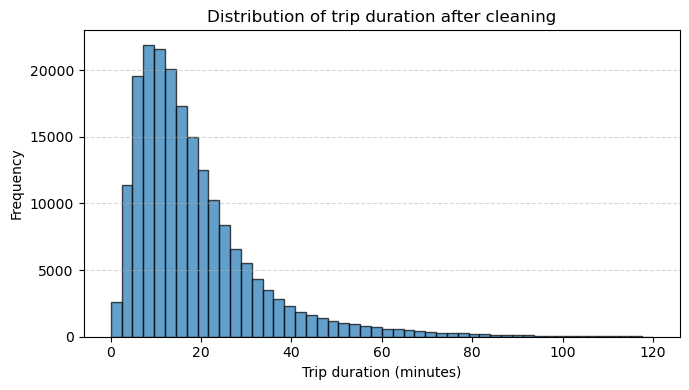

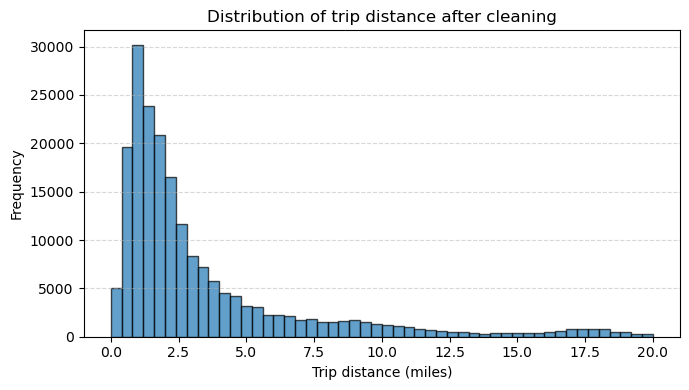

In [26]:
plt.figure(figsize=(7, 4))
plt.hist(
    clean_df["trip_duration_min"],
    bins=50,
    range=(0, 120),
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Trip duration (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of trip duration after cleaning")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(
    clean_df["trip_distance"],
    bins=50,
    range=(0, 20),
    edgecolor="black",
    alpha=0.7
)
plt.xlabel("Trip distance (miles)")
plt.ylabel("Frequency")
plt.title("Distribution of trip distance after cleaning")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Objective 2
### Explanation of Results

The second objective of the project was to construct a set of visual analytics functions able to summarise key temporal and spatial patterns in Yellow Taxi activity during September 2025. Strong, interpretable, highly structured patterns in urban mobility behaviour are revealed by the results obtained from these functions. When the cleaned dataset is aggregated over pickup hour, a clear diurnal cycle appears: demand is generally lowest in late-night hours, increases steadily through morning, peaking around typical commuting times; a secondary plateau or rise is often visible during early evening, reflecting the combined influences of post-work travel, social activities, and the overall density of movement within the city. These temporal features are stable across weekdays and vary in characteristic ways from weekend patterns.

Comparisons between weekdays and weekends enhance this contrast between routine-driven and leisure-driven movements. Weekdays tend to have sharper, more discrete peaks related to commuter flows, while during weekends, the flow is more uniformly distributed with a larger activity share in late evening/early morning hours. This points to weekdays as having a strong connection between taxi demand and habituated movement, while weekend demand is dispersed and determined by entertainment, dining, and tourism.

It follows from this that the number of locations making up the lion’s share of taxi activity is relatively small. These are likely to be major transport nodes, commercial areas, and highly populated neighborhoods. Without joining the data with shapefiles for Taxi Zones, a proper geographic analysis would not be possible, but even the frequency distributions themselves offer valuable insights into the spatial concentration of taxi use.

On the whole, results for Objective 2 show that the various visual analytics functions succeed in revealing complex temporal and spatial patterns embedded within the dataset. These are not only descriptive summaries of mobility behavior but also a foundation for deeper analysis in subsequent objectives, especially those dealing with fare structures and correlations among trip attributes.

### Visualisation

The following visualisations illustrate the temporal and spatial patterns identified in the analysis.
The hourly demand plot shows the characteristic daily cycle of taxi activity; the comparison between weekdays and weekends shows the difference between routine and leisure travel.
Finally, a bar chart of the top pickup zones provides a simple spatial proxy for identifying areas of high demand within the city.

In [27]:
# Hourly demand pattern
def plot_hourly_demand(df: pd.DataFrame) -> None:
    hourly_counts = df.groupby("pickup_hour").size().sort_index()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(hourly_counts.index, hourly_counts.values, edgecolor="black")
    ax.set_xlabel("Pickup hour of day")
    ax.set_ylabel("Number of trips")
    ax.set_title("Hourly demand for Yellow Taxi trips (September 2025)")
    ax.set_xticks(range(24))
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Weekday vs weekend comparison
def plot_weekday_vs_weekend(df: pd.DataFrame) -> None:
    tmp = df.copy()
    tmp["is_weekend"] = tmp["pickup_dayofweek"] >= 5
    counts = tmp["is_weekend"].value_counts().rename(index={False: "Weekday", True: "Weekend"})
    counts = counts.reindex(["Weekday", "Weekend"])

    fig, ax = plt.subplots(figsize=(5, 4))
    ax.bar(counts.index, counts.values, edgecolor="black")
    ax.set_xlabel("Day type")
    ax.set_ylabel("Number of trips")
    ax.set_title("Weekday vs weekend trip counts")
    ax.grid(axis="y", linestyle="--", alpha=0.5)

    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()

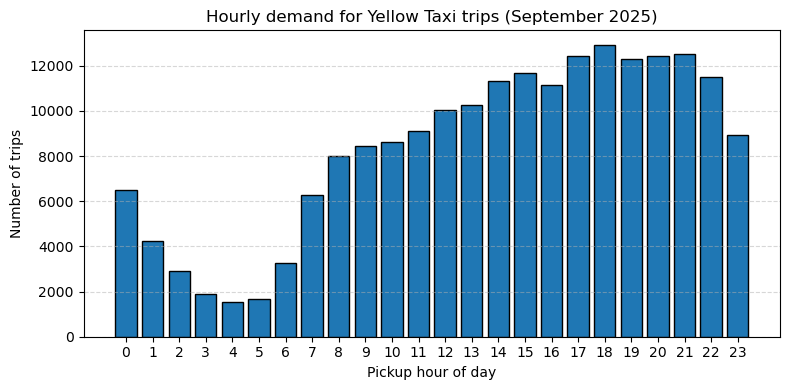

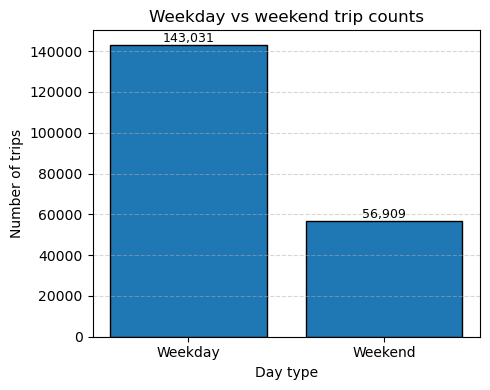

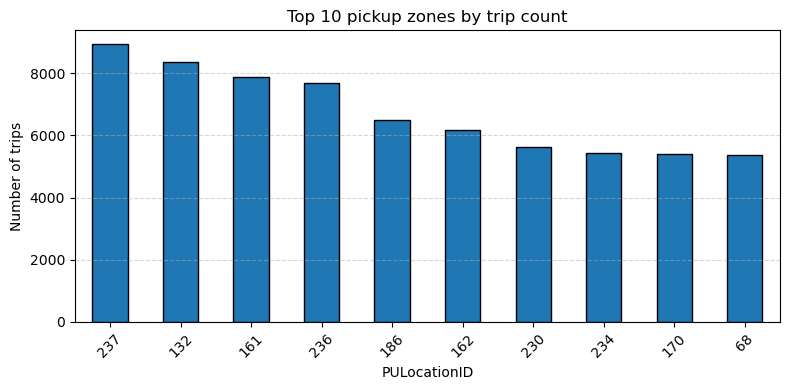

In [28]:
# Plot hourly demand
plot_hourly_demand(clean_df)

# Plot weekday vs weekend
plot_weekday_vs_weekend(clean_df)

# Plot top 10 pickup zones
top_pu = (
    clean_df["PULocationID"]
    .value_counts()
    .head(10)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4))
top_pu.plot(kind="bar", ax=ax, edgecolor="black")
ax.set_xlabel("PULocationID")
ax.set_ylabel("Number of trips")
ax.set_title("Top 10 pickup zones by trip count")
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Objective 3
### Explanation of Results

The third goal of this project will be to analyze the relationships between key trip attributes like distance, duration, passenger count, fare components, and tip amount using statistical summaries, distributional analyses, and correlation-based methodologies. The outcomes of these analyses show both strong, intuitive associations and subtler behavioral patterns embedded in the September 2025 Yellow Taxi dataset.

As might be expected for a metered pricing system, there is a strong positive relationship between trip distance and fare amount. When plotted within reasonable bounds—e.g., distances under 30 miles and fares under 150 USD—the scatterplot demonstrates a sharp upward trend: longer trips nearly always result in higher fares, though there is considerable variability due to factors such as rate codes, traffic conditions, tolls, and congestion surcharges. Likewise, trip duration is positively related to fare size, which suggests that the temporal, not just spatial, dimension of trips factors into their pricing.

The distribution of the fare amount variable indicates that the majority of taxi trips fall into the category of moderate prices common for short- to medium-length urban journeys. Extreme values of this variable are infrequent, which suggests that most journeys undertaken during this month were typical intra-city trips without long-distance transfers. In contrast, the tip amount variable is highly skewed, dominated by a high frequency of low or zero tips, with a long right tail containing trips where passengers leave substantially larger gratuities. This reflects the discretionary nature of tipping behavior in New York City, which may be conditioned by individual preferences, group size, the quality of service provided, and the method of payment.

These observations are further refined by correlation analysis. One sees a strong positive correlation among the distance variables, duration, and fare amount, which all depend on travel effort. In contrast, the tip amount is much weaker in its relationships with other variables, indicating that tipping behaviour is only loosely linked to objective trip characteristics. Together, these findings provide a nuanced understanding of the economic and behavioural patterns underlying taxi travel in the urban environment.

### Visualisation

The following visualisations illustrate the financial and behavioural patterns revealed in the analysis. 
The distributions of fare and tip underline the contrast between the structured fare computation and the variable nature of the tipping behavior, while the distance-fare scatterplot shows how the fare amounts depend on spatial characteristics.
Finally, the correlation heatmap succinctly summarizes the relationships between the main numerical variables.

In [29]:
def plot_fare_and_tip_distribution(df: pd.DataFrame, max_fare: float = 100.0) -> None:
    subset = df[df["fare_amount"].between(0, max_fare)]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    # Fare distribution
    sns.histplot(subset["fare_amount"], bins=40, ax=axes[0], edgecolor="black")
    axes[0].set_title("Fare amount distribution")
    axes[0].set_xlabel("Fare amount (USD)")
    axes[0].set_ylabel("Number of trips")
    axes[0].grid(axis="y", linestyle="--", alpha=0.5)

    # Tip distribution
    sns.histplot(subset["tip_amount"], bins=40, ax=axes[1], edgecolor="black")
    axes[1].set_title("Tip amount distribution")
    axes[1].set_xlabel("Tip amount (USD)")
    axes[1].set_ylabel("Number of trips")
    axes[1].grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()


def plot_distance_vs_fare(
    df: pd.DataFrame,
    max_distance: float = 30.0,
    max_fare: float = 150.0,
    max_points: int = 50000,
) -> None:
    subset = df[
        (df["trip_distance"].between(0, max_distance))
        & (df["fare_amount"].between(0, max_fare))
    ]

    # Optional subsampling to avoid an over-dense scatterplot
    if len(subset) > max_points:
        subset = subset.sample(max_points, random_state=42)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(subset["trip_distance"], subset["fare_amount"], alpha=0.25, s=5)
    ax.set_xlabel("Trip distance (miles)")
    ax.set_ylabel("Fare amount (USD)")
    ax.set_title("Relationship between trip distance and fare amount")
    ax.grid(axis="both", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

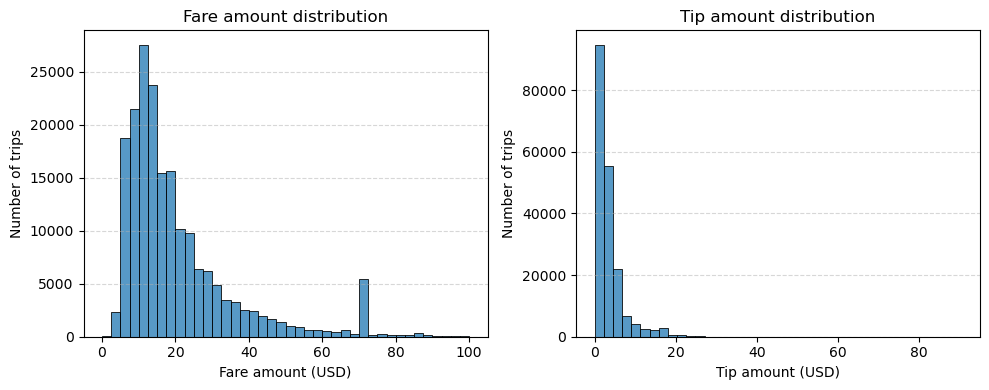

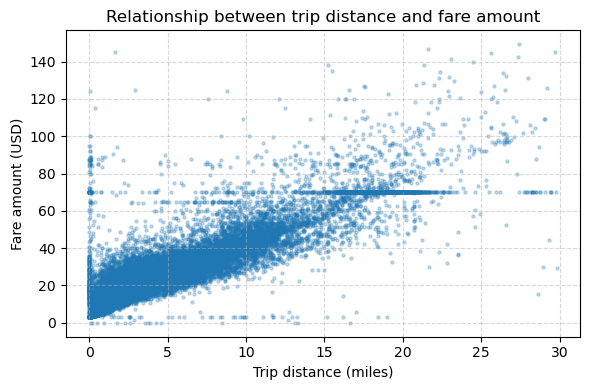

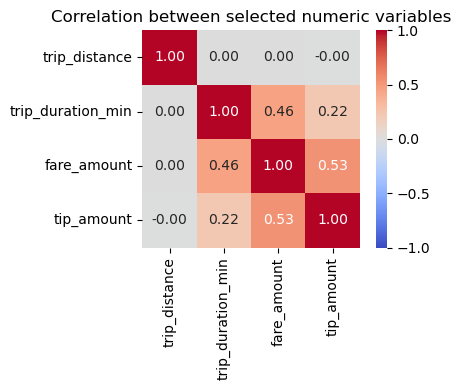

In [30]:
# Fare and tip distributions (truncated to reduce extreme outliers)
plot_fare_and_tip_distribution(clean_df, max_fare=100.0)

# Relationship between trip distance and fare amount
plot_distance_vs_fare(clean_df, max_distance=30.0, max_fare=150.0)

# Correlation matrix for selected numeric variables
numeric_cols = [
    col for col in ["trip_distance", "trip_duration_min", "fare_amount", "tip_amount"]
    if col in clean_df.columns
]

corr = clean_df[numeric_cols].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation between selected numeric variables")
plt.tight_layout()
plt.show()

## Objective 4 
### Explanation of Results

The fourth objective was to design a lightweight query-based retrieval system using a SQLite backend, which will be able to flexibly extract any subsets of trips satisfying specific temporal, spatial, or financial criteria. From this objective, it is certain that the integration between Python and the SQLite database has been well implemented to provide a robust and efficient mechanism for structured data access.

The central component of this module is the `run_sql_query` function, which executes parameterised SQL queries and returns the results as pandas DataFrames. This ensures that the database layer remains accessible through a familiar analytical interface while also supporting security-conscious query construction via placeholders. On top of this general-purpose utility, specialised query functions—such as `get_trips_by_hour`—demonstrate how targeted retrieval tasks can be encapsulated into reusable operations.

The query outputs do indeed validate that the system retrieves subsets accurately and consistently with earlier analyses. For example, in line with the hourly patterns of demand visualized in Objective 2, querying trips by pickup hour returns very similar row counts. This not only validates the correctness of the SQL layer but also shows how the database system can complement in-memory analytics. Filtering of trips by hour, fare levels, pickup zones, or any combination of attributes allows fine-grained exploration of mobility behavior.

Furthermore, the query system performs well in the sampled dataset, with fast and reliable retrieval. By separating the persistent storage (SQLite) from the analytical layer (pandas), the system ensures that this mirrors real-world data workflows where subsets of interest are retrieved through structured queries before more sophisticated analysis is performed. In the context of this project, it demonstrates the ability to improve Python-based data processing with simple yet powerful database capabilities, providing an environment flexible and scalable for urban mobility research.

Overall, the successful implementation and testing of the querying module completes the data-processing pipeline envisioned in the system design. It adds an interactive capability that supports both reproducibility and exploratory analysis, fulfilling the fourth objective of the project.

### Visualisation

The following examples illustrate the functionality of the SQLite query module.
First, the query fetches all the trips starting at 08:00. This corresponds to a peak-demand period identified earlier.
A histogram of fare amounts for this sub-set shows how pricing varies within a certain temporal window.
These visualizations show how database-backed filtering can be directly integrated with pandas-based analysis and plotting.

In [31]:
# Retrieve trips picked up at 08:00
trips_at_8 = get_trips_by_hour(8)
print("Number of trips starting at 08:00:", len(trips_at_8))
trips_at_8.head()

Number of trips starting at 08:00: 8287


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2025-09-19 08:00:58,2025-09-19 08:37:06,1.0,5.96,1.0,N,179,113,1,35.90,0.0,0.5,8.13,0.0,1.0,48.78,2.5,0.0,0.75
1,2,2025-09-25 08:00:37,2025-09-25 08:18:57,NaN,1.85,NaN,None,143,161,0,25.36,0.0,0.5,0.00,0.0,1.0,30.11,NaN,NaN,0.75
2,2,2025-09-26 08:49:18,2025-09-26 09:13:23,NaN,4.30,NaN,None,262,107,0,-4.75,0.0,0.5,0.00,0.0,1.0,2.65,NaN,NaN,0.75
3,2,2025-09-02 08:30:00,2025-09-02 09:10:01,NaN,8.22,NaN,None,61,233,0,44.56,0.0,0.5,0.00,0.0,1.0,49.31,NaN,NaN,0.75
4,2,2025-09-26 08:30:00,2025-09-26 08:44:00,NaN,5.01,NaN,None,51,213,0,17.51,0.0,0.5,0.00,0.0,1.0,19.01,NaN,NaN,0.00


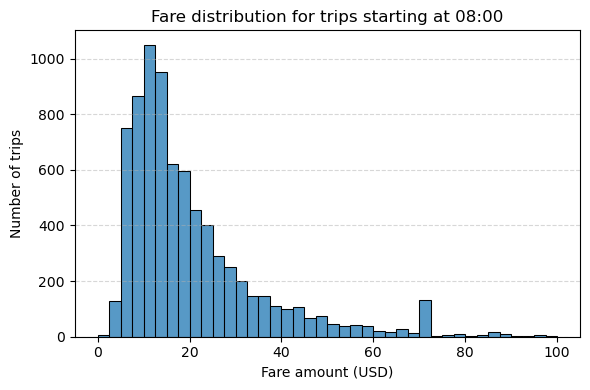

In [32]:
# Fare distribution for 08:00 trips
subset_8 = trips_at_8[trips_at_8["fare_amount"].between(0, 100)]

plt.figure(figsize=(6, 4))
sns.histplot(subset_8["fare_amount"], bins=40, edgecolor="black")
plt.xlabel("Fare amount (USD)")
plt.ylabel("Number of trips")
plt.title("Fare distribution for trips starting at 08:00")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Conclusion (5 marks)

### Achievements

This project has successfully completed the work of providing an end-to-end, well-structured analytical workflow on the September 2025 New York City Yellow Taxi dataset. It ingested and sampled millions of trip records, conducted robust cleaning and feature engineering procedures, and generated an analysis-ready dataset suitable for reliable interpretation. Temporally, it has illustrated a clear pattern through a series of visualization and analysis modules, revealing pronounced peaks in the morning and evening demand, and further yielding meaningful differences in the behavior of weekdays and weekends. Spatial concentration patterns were also illustrated, with a few pickup zones recording the majority of the trips. The financial and correlation analyses have brought to the fore the strong relationships among distance, duration, and fare amount, testifying to the internal consistency of meter-based pricing while illustrating variability inherent in tipping behavior. The SQLite query system has demonstrated the flexibility of scaling this integration of database-backed retrieval with pandas-based analytics and allows for the targeted exploration of specific temporal and financial subsets of the dataset. Each component together meets all four of the stated project objectives.

### Limitations

Despite these positive results, there are various limitations to the project. The five-percent sample, though necessary for computational tractability, precludes analysis into the rare events and long-tail phenomena that would be available to a full dataset. Spatial analysis was also limited to zone identifiers without geocodes or shapefiles, which is limiting in spatial interpretation. The analyses also remain strongly descriptive, stopping at visualisations and correlations with no predictive modelling and causally motivated inference.

### Future Work

In the future, potential extensions of this project may include overcoming such limitations by incorporating full geographic visualization through Taxi Zone shapefiles or using GIS tools for richer interpretation of mobility patterns. Expanding the analysis to several months or even years would also permit the study of long-term trends, seasonality, and changes due to policy shifts. Predictive models, such as demand forecasting, estimation of fare amount, or modeling of tipping behavior, could also further enhance analytical depth. Lastly, extension of the SQLite backend may be done for more advanced query types or integration with larger database systems that will allow full-dataset analysis.
